# 06 - Task 5: from digital shadow to digital twin

**Brief:** *appraisal on how the knowledge developed as part of the construction of a digital shadow
can evolve into the design specifications of a digital twin of the fuel system.*

This notebook does that in two halves:

* **Build and test the shadow.** Everything learned in notebooks 02-05 is assembled into a running
  assessment (`fueltwin.twin.DigitalShadow`) and the whole test day is replayed through it as if it
  were a live data stream. A physics model of the rig is used to train a classifier without a single
  real fault label, and is then tested on the real recordings.
* **Turn the lessons into a specification.** What the shadow could not do, and why, becomes the
  requirements for a digital twin. The full specification is in `docs/task5_digital_twin_design.md`;
  the key tables are reproduced at the end.

## Where the current system sits

Kritzinger et al. (2018) separate three levels by how data moves between the physical and the
digital object: a **digital model** (manual data exchange both ways), a **digital shadow** (automatic
flow from asset to model only) and a **digital twin** (automatic flow both ways, the digital object
can act on the physical one). DNV-RP-A204 (DNV, 2020) grades each function of a twin by capability:
0 standalone, 1 descriptive, 2 diagnostic, 3 predictive, 4 prescriptive, 5 autonomous.

| | Before this project | This project | Digital twin target |
|---|---|---|---|
| Integration (Kritzinger) | digital model: files exported and analysed by hand | digital shadow, replayed offline | digital twin: live, with feedback to the speed drive and valves |
| Capability (DNV) | 1 descriptive | 2 diagnostic, first steps of 4 (what-if) | 3 predictive and 4 prescriptive |

In [1]:
from collections import deque

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.patches import FancyArrowPatch, FancyBboxPatch
from sklearn.ensemble import HistGradientBoostingClassifier
from sklearn.metrics import confusion_matrix

from fueltwin import config, diagnosis as dg, features, hydraulics as hy, plotting as pl, simulate as sm, twin

pl.use_style()
pd.set_option("display.precision", 3)
pd.set_option("display.width", 170)
w = features.load_windows(1.0)
FAULTS = list(config.FAULTS)

## 1. Architecture of the shadow

Mapped onto the five-dimension model of Tao et al. (2019): physical entity (PE), virtual entity
(VE), services (Ss), twin data (DD) and connections (CN).

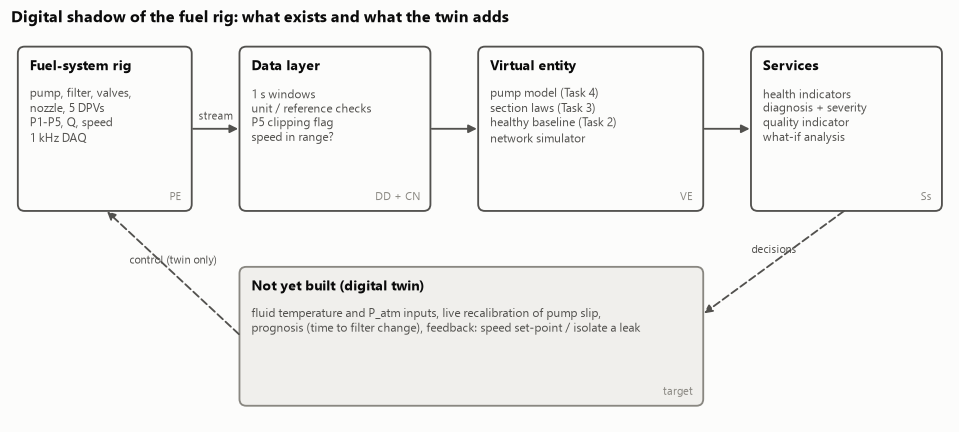

In [2]:
fig, ax = plt.subplots(figsize=(11, 4.6))
ax.set_xlim(0, 11)
ax.set_ylim(0, 4.6)
ax.axis("off")


def node(x, y, w_, h, title, body, tag, fc=pl.SURFACE, ec=pl.INK_2):
    ax.add_patch(FancyBboxPatch((x, y), w_, h, boxstyle="round,pad=0.02,rounding_size=0.08", fc=fc, ec=ec, lw=1.2))
    ax.text(x + 0.12, y + h - 0.14, title, fontsize=9, fontweight="bold", va="top", color=pl.INK)
    ax.text(x + 0.12, y + h - 0.45, body, fontsize=7.6, va="top", color=pl.INK_2, linespacing=1.35)
    ax.text(x + w_ - 0.1, y + 0.08, tag, fontsize=7.5, ha="right", va="bottom", color=pl.MUTED)


def arrow(x0, y0, x1, y1, text="", dashed=False):
    ax.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle="-|>", mutation_scale=11, lw=1.2,
                                 color=pl.INK_2, ls=(0, (4, 2)) if dashed else "-"))
    if text:
        ax.text((x0 + x1) / 2, (y0 + y1) / 2 + 0.08, text, fontsize=7.5, ha="center", va="bottom", color=pl.INK_2)


node(0.1, 2.5, 2.0, 1.9, "Fuel-system rig", "pump, filter, valves,\nnozzle, 5 DPVs\nP1-P5, Q, speed\n1 kHz DAQ", "PE")
node(2.7, 2.5, 2.2, 1.9, "Data layer", "1 s windows\nunit / reference checks\nP5 clipping flag\nspeed in range?", "DD + CN")
node(5.5, 2.5, 2.6, 1.9, "Virtual entity", "pump model (Task 4)\nsection laws (Task 3)\nhealthy baseline (Task 2)\nnetwork simulator", "VE")
node(8.7, 2.5, 2.2, 1.9, "Services", "health indicators\ndiagnosis + severity\nquality indicator\nwhat-if analysis", "Ss")
node(2.7, 0.2, 5.4, 1.6, "Not yet built (digital twin)", "fluid temperature and P_atm inputs, live recalibration of pump slip,\n"
     "prognosis (time to filter change), feedback: speed set-point / isolate a leak", "target",
     fc="#f0efec", ec=pl.MUTED)
arrow(2.1, 3.45, 2.7, 3.45, "stream")
arrow(4.9, 3.45, 5.5, 3.45)
arrow(8.1, 3.45, 8.7, 3.45)
arrow(9.8, 2.5, 8.1, 1.25, "decisions", dashed=True)
arrow(2.7, 1.0, 1.1, 2.5, "control (twin only)", dashed=True)
ax.set_title("Digital shadow of the fuel rig: what exists and what the twin adds", loc="left")
pl.save(fig, "06_architecture")
plt.show()

## 2. Calibrating the shadow without peeking

The shadow needs three things identified on the asset: the section laws and pump line (notebook 03),
their limits, and a classifier for the second opinion. To score it honestly on fault Fx, every one of
them is built **without any Fx recording** (leave-one-fault-out). The classifier is trained only on
synthetic windows from the network model (`fueltwin.simulate`), which joins the identified component
laws and injects each fault over a wide range of severities, with random drift in pump delivery
(sd 1.5 %) and tank level, plus measurement noise taken from the healthy runs.

First, a check that the network model behaves like the rig: simulated against measured at the
strongest recorded settings.

In [3]:
rig_all = sm.RigModel.from_windows(w)
runs = features.run_means(w).set_index("run_id")
check = []
for kw, run in [({}, "HC-3"), ({"s_f": 20}, "F1-080"), ({"g_b": 2.0}, "F2-100"), ({"s_v": 11}, "F3-080"),
                ({"g_l": 2.0}, "F4-090"), ({"s_n": 8.5}, "F5-080")]:
    o = rig_all.solve(**kw)
    check.append({"recording": run, "fault parameter": ", ".join(f"{k}={v}" for k, v in kw.items()) or "healthy",
                  **{f"{c} sim": o[c] for c in ["P2", "P3", "P4", "Q"]},
                  **{f"{c} real": runs.loc[run, c] for c in ["P2", "P3", "P4", "Q"]}})
pd.DataFrame(check).set_index("recording").round(3)

,fault parameter,P2 sim,P3 sim,P4 sim,Q sim,P2 real,P3 real,P4 real,Q real
recording,,,,,,,,,
HC-3,healthy,0.862,1.322,1.224,0.707,0.867,1.334,1.234,0.716
F1-080,s_f=20,0.371,1.193,1.136,0.550,0.349,1.205,1.144,0.568
F2-100,g_b=2.0,0.845,1.074,1.056,0.315,0.822,1.053,1.035,0.347
F3-080,s_v=11,0.884,1.734,1.130,0.538,0.897,1.766,1.127,0.557
F4-090,g_l=2.0,0.852,1.177,1.060,0.332,0.850,1.170,1.061,0.346
F5-080,s_n=8.5,0.884,1.716,1.660,0.545,0.901,1.708,1.648,0.537


The fault parameters here (resistance multipliers, bypass and leak conductances) are chosen by hand to
show the model can reach each recorded state; they are **not** used for training. Training data is
drawn at random over physically motivated ranges (blockages up to 25x resistance, bypass or leak up to
about two thirds of the pump's flow).

In [4]:
hc = w[w["condition"] == "HC"]
noise = hc.groupby("run_id")[dg.RAW].std().mean()
rng = np.random.default_rng(42)
shadows, sims = {}, {}
for held in FAULTS + [None]:
    rmod = sm.RigModel.from_windows(w, exclude=held)
    sim = sm.sample_faults(rmod, 400, noise, rng)
    clf = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=0).fit(sim[dg.RAW], sim["condition"])
    shadows[held] = twin.DigitalShadow(hy.ResidualModel.fit(w, exclude=held), classifier=clf)
    sims[held] = sim
print("synthetic windows per calibration:", len(sims[None]), "| converged share:",
      f"{len(sims[None]) / (6 * 400):.0%}")

synthetic windows per calibration: 2400 | converged share: 100%


## 3. Replaying the test day through the shadow

All 2 820 windows are fed in time order, as one continuous stream from 09:58 to 16:12. The alarm state
changes only when five consecutive windows agree. Each recording is assessed by the shadow that was
calibrated without its fault (healthy recordings by the shadow calibrated on everything, a stated
limitation: there is no healthy data the calibration did not see).

In [5]:
w_sorted = w.sort_values("clock")
parts = []
stream_shadow = None
prev_alarm, prev_hist = "HC", []
for run_id, g in w_sorted.groupby("run_id", sort=False):
    cond = g["condition"].iloc[0]
    sh = shadows[cond if cond in FAULTS else None]
    sh._alarm, sh._history = prev_alarm, deque(prev_hist, maxlen=60)
    out = sh.stream(g).rename(columns={"severity": "severity_phys"})
    prev_alarm, prev_hist = sh._alarm, list(sh._history)
    parts.append(pd.concat([g[["run_id", "condition", "severity", "clock"]], out], axis=1))
day = pd.concat(parts)
day.to_parquet(config.REPO_ROOT / "results" / "tables" / "06_shadow_replay.parquet")
print(day["quality"].value_counts())

quality
green     2161
yellow     659
Name: count, dtype: int64


In [6]:
summary = day.groupby("run_id", sort=False).agg(
    condition=("condition", "first"), severity=("severity", "first"), start=("clock", "first"),
    rules=("rules", lambda s: s.value_counts().index[0]), classifier=("classifier", lambda s: s.value_counts().index[0]),
    alarm_at_end=("alarm", "last"),
    windows_to_correct_alarm=("alarm", lambda s: np.nan),
    green=("quality", lambda s: (s == "green").mean()), yellow=("quality", lambda s: (s == "yellow").mean()),
    red=("quality", lambda s: (s == "red").mean()),
    severity_physical=("severity_phys", "median"))
for run_id, g in day.groupby("run_id", sort=False):
    hit = np.flatnonzero(g["alarm"].to_numpy() == g["condition"].iloc[0])
    summary.loc[run_id, "windows_to_correct_alarm"] = hit[0] if len(hit) else np.nan
summary["start"] = summary["start"].dt.strftime("%H:%M")
summary.to_csv(config.TABLE_DIR / "06_shadow_per_recording.csv")
summary

,condition,severity,start,rules,classifier,alarm_at_end,windows_to_correct_alarm,green,yellow,red,severity_physical
run_id,,,,,,,,,,,
HC-1,HC,0.0,09:58,HC,HC,HC,0.0,0.883,0.117,0.0,NaN
HC-2,HC,0.0,09:59,HC,HC,HC,0.0,0.800,0.200,0.0,NaN
HC-3,HC,0.0,10:00,HC,HC,HC,0.0,0.967,0.033,0.0,NaN
HC-4,HC,0.0,10:01,HC,HC,HC,0.0,0.950,0.050,0.0,NaN
HC-5,HC,0.0,10:02,HC,HC,HC,0.0,0.833,0.167,0.0,NaN
HC-6,HC,0.0,10:03,HC,HC,HC,0.0,0.700,0.300,0.0,NaN
F1-010,F1,10.0,10:04,HC,HC,HC,25.0,0.517,0.483,0.0,1.143
F1-020,F1,20.0,10:11,F1,F1,F1,4.0,1.000,0.000,0.0,1.380
F1-030,F1,30.0,10:19,F1,F1,F1,0.0,1.000,0.000,0.0,1.878


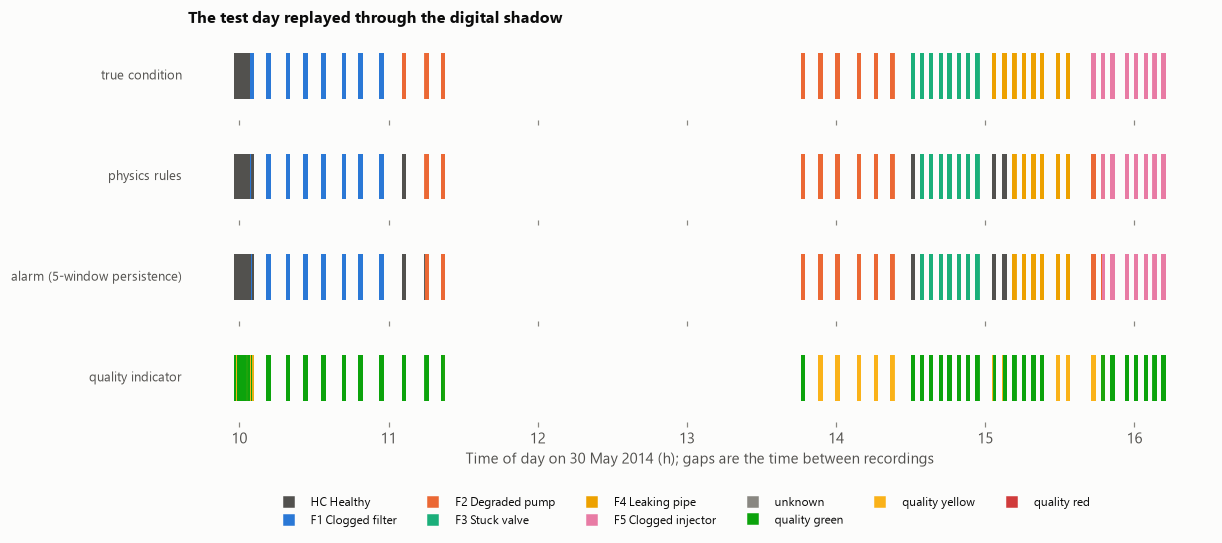

In [7]:
cols = {c: pl.CONDITION_COLORS[c] for c in config.CONDITIONS} | {"unknown": pl.MUTED}
qcol = {"green": pl.STATUS["good"], "yellow": pl.STATUS["warning"], "red": pl.STATUS["critical"]}
tod = day["clock"].dt.hour + day["clock"].dt.minute / 60 + day["clock"].dt.second / 3600
fig, axes = plt.subplots(4, 1, figsize=(12, 4.6), sharex=True, gridspec_kw={"hspace": 0.15})
rows_ = [("true condition", day["condition"], cols), ("physics rules", day["rules"], cols),
         ("alarm (5-window persistence)", day["alarm"], cols), ("quality indicator", day["quality"], qcol)]
for ax, (name, s, cmap) in zip(axes, rows_):
    ax.scatter(tod, np.zeros(len(tod)), c=[cmap.get(v, pl.MUTED) for v in s], marker="|", s=900, linewidths=1.2)
    ax.set_yticks([])
    ax.set_ylabel(name, rotation=0, ha="right", va="center", fontsize=8.5)
    ax.grid(False)
    for sp in ("left", "bottom"):
        ax.spines[sp].set_visible(False)
axes[-1].set_xlabel("Time of day on 30 May 2014 (h); gaps are the time between recordings")
from matplotlib.lines import Line2D
handles = [Line2D([], [], marker="s", ls="", color=c, label=f"{k} {config.CONDITION_NAMES.get(k, '')}".strip())
           for k, c in cols.items()] + [Line2D([], [], marker="s", ls="", color=c, label=f"quality {k}") for k, c in qcol.items()]
fig.legend(handles=handles, ncol=6, loc="lower center", bbox_to_anchor=(0.5, -0.12), fontsize=8)
axes[0].set_title("The test day replayed through the digital shadow", loc="left")
pl.save(fig, "06_day_replay")
plt.show()

**How the shadow performs over the day**

In [8]:
by_cond = summary.assign(correct=summary["alarm_at_end"] == summary["condition"])
headline = {
    "healthy windows with a fault alarm": int(((day["condition"] == "HC") & (day["alarm"] != "HC")).sum()),
    "recordings whose alarm ends on the right condition": f"{int(by_cond['correct'].sum())}/{len(by_cond)}",
    "same, excluding the 3 settings with no physical effect": f"{int(by_cond.drop(['F2-020', 'F4-020', 'F4-030'])['correct'].sum())}/44",
    "median windows to a correct alarm (when reached)": float(summary["windows_to_correct_alarm"].median()),
    "windows rated green / yellow / red": " / ".join(f"{(day['quality'] == q).mean():.0%}" for q in ["green", "yellow", "red"]),
}
pd.Series(headline, name="value").to_frame()

,value
healthy windows with a fault alarm,0
recordings whose alarm ends on the right condition,41/47
"same, excluding the 3 settings with no physical effect",41/44
median windows to a correct alarm (when reached),0.0
windows rated green / yellow / red,77% / 23% / 0%


* **No false alarms**: no healthy window raised a fault alarm, and the alarm ends on the right
  condition for 41 of 47 recordings. Three of the six misses are the settings with no physical effect
  (F2 20 %, F4 20 % and 30 %), where "healthy" is the physically right answer. Two are the mildest
  blockage settings (F1 10 %, F3 10 %), which the persistence rule holds back on purpose. The sixth
  is F5 10 %, which the rules call a pump fault because of the afternoon drift.
* At the first setting where each fault becomes visible, the alarm switches after 4 windows (the
  5-window persistence rule); F5 at 20 %, where the evidence flickers, needed 26 windows.
* The **quality indicator does its job on the hard cases**: every window of the F5 10 % recording is
  rated **yellow** ("rules and classifier disagree; small pump shortfall: drift or early pump/leak
  fault"), and the strongest F2/F4 settings, where P5 is clipped, are flagged too. A maintainer would
  see "probably a pump or leak problem, low confidence" rather than a confident wrong answer.
* The price is some yellow on healthy windows (3-30 % per recording), where the simulation-trained
  second opinion disagrees with the rules (section 4 explains why).

## 4. Can a physics model replace fault data? (sim-to-real)

Ritto and Rochinha (2021) propose building a twin's classifier from a physics-based model, so it can
recognise damage that has never been observed. Here the classifier inside the shadow was trained on
synthetic windows only. Scored on the real recordings:

In [9]:
def sim_to_real(seed: int, n_per_class: int = 400):
    """Train on synthetic windows only (leave-one-fault-out calibration), predict every real window."""
    rng_ = np.random.default_rng(seed)
    preds_ = {"raw": pd.Series(index=w.index, dtype=object), "physics": pd.Series(index=w.index, dtype=object)}
    for held in FAULTS + [None]:
        idx = w.index[w["condition"] == held] if held else w.index[w["condition"] == "HC"]
        rmod = sm.RigModel.from_windows(w, exclude=held)
        rm_ = hy.ResidualModel.fit(w, exclude=held)
        sim = sm.sample_faults(rmod, n_per_class, noise, rng_)
        for fs, (xs, xt) in {"raw": (sim[dg.RAW], w.loc[idx, dg.RAW]),
                             "physics": (rm_.normalised(sim), rm_.normalised(w.loc[idx]))}.items():
            clf_ = HistGradientBoostingClassifier(max_iter=300, learning_rate=0.05, random_state=seed).fit(xs, sim["condition"])
            preds_[fs].loc[idx] = clf_.predict(xt)
    return preds_


empty = w["run_id"].isin(["F2-020", "F4-020", "F4-030"])
is_hc = w["condition"] == "HC"
rows, keep = [], {}
for seed in range(5):
    pr = sim_to_real(seed)
    for fs, p in pr.items():
        sc = dg.score(w["condition"], p, w["run_id"])
        rows.append({"seed": seed, "features": fs, "macro_f1": sc["macro_f1"],
                     "macro_f1 without 3 empty settings": dg.score(w["condition"][~empty], p[~empty])["macro_f1"],
                     "recordings correct": int(sc["recordings_correct"].split("/")[0]),
                     "healthy windows flagged as faulty": float((p[is_hc] != "HC").mean())})
        keep[(seed, fs)] = p
s2r = pd.DataFrame(rows)
s2r.to_csv(config.TABLE_DIR / "06_sim_to_real_seeds.csv", index=False)
s2r.groupby("features").agg(["mean", "std", "min", "max"]).drop(columns="seed").round(3).T

features                                physics     raw
macro_f1                          mean    0.847   0.869
                                  std     0.035   0.032
                                  min     0.790   0.829
                                  max     0.884   0.900
macro_f1 without 3 empty settings mean    0.905   0.927
                                  std     0.039   0.034
                                  min     0.840   0.885
                                  max     0.944   0.961
recordings correct                mean   40.600  41.200
                                  std     2.191   1.095
                                  min    37.000  40.000
                                  max    42.000  42.000
healthy windows flagged as faulty mean    0.466   0.191
                                  std     0.240   0.260
                                  min     0.128   0.000
                                  max     0.781   0.531

In [10]:
best_fs = s2r.groupby("features")["macro_f1"].mean().idxmax()
med_seed = s2r[s2r["features"] == best_fs].sort_values("macro_f1").iloc[2]["seed"]
real_pred = keep[(int(med_seed), best_fs)]
print(f"Confusion matrix below: {best_fs} features, the median of the five seeds (seed {int(med_seed)}).")

Confusion matrix below: raw features, the median of the five seeds (seed 0).


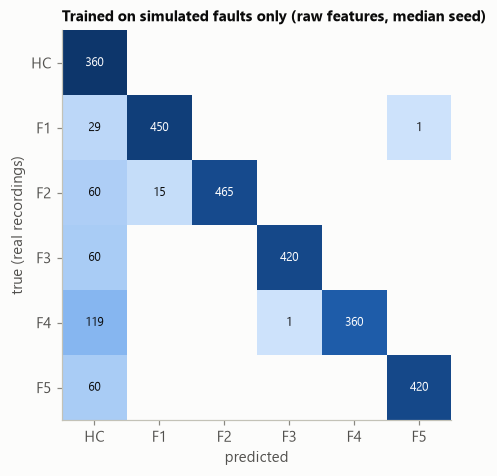

In [11]:
fig, ax = plt.subplots(figsize=(5.6, 4.6))
cm = confusion_matrix(w["condition"], real_pred.astype(str), labels=dg.LABELS)
cmn = cm / cm.sum(axis=1, keepdims=True)
cmap = pl.BLUE_RAMP.copy()
cmap.set_bad(pl.SURFACE)
ax.imshow(np.ma.masked_where(cm == 0, cmn), cmap=cmap, vmin=0, vmax=1)
for i in range(6):
    for j in range(6):
        if cm[i, j]:
            ax.text(j, i, cm[i, j], ha="center", va="center", fontsize=8, color="white" if cmn[i, j] > 0.55 else pl.INK)
ax.set_xticks(range(6), dg.LABELS)
ax.set_yticks(range(6), dg.LABELS)
ax.set_xlabel("predicted")
ax.set_ylabel("true (real recordings)")
ax.set_title(f"Trained on simulated faults only ({best_fs} features, median seed)", fontsize=9.5)
ax.grid(False)
pl.save(fig, "06_sim_to_real_confusion")
plt.show()

**Fault isolation transfers from physics to reality.** The classifier never saw a real fault window
and has no access to the clock; its only knowledge of the faults comes from the rig's physics. With
raw pressures it reaches a macro F1 of **0.87 +/- 0.03** over five seeds (0.93 without the three
settings that have no physical effect) and names 40-42 of the 47 recordings correctly. When it
misses a fault, it mostly calls a mild setting healthy, the safe direction of error. This is the
cleanest evidence of diagnostic skill in the project, because the time shortcut cannot reach it.

**Its healthy boundary does not transfer yet.** Depending on the seed, 0-53 % of the real healthy
windows (mean 19 %) are called faulty, mostly a clogged injector, and residual features make this
worse (mean 47 %). The simulated noise and drift do not reproduce the real healthy scatter, so the
classifier's healthy region ends up in the wrong place. Matching simulated noise and drift to reality
is the model-qualification step DNV-RP-A204 requires before a functional element is trusted, and it
is the main piece of work left on this part of the twin.

That is why the classifier is only a **second opinion** inside the shadow: disagreement lowers the
quality indicator but never raises an alarm on its own, and the replay above has no false alarms.

## 5. Using the virtual entity: what-if questions

A twin earns its keep by answering questions that cannot safely be tested on the asset. Two
examples with the calibrated network model:

**How far can the filter clog before the system is in trouble?** Sweep the filter resistance and
watch delivered flow and suction pressure.

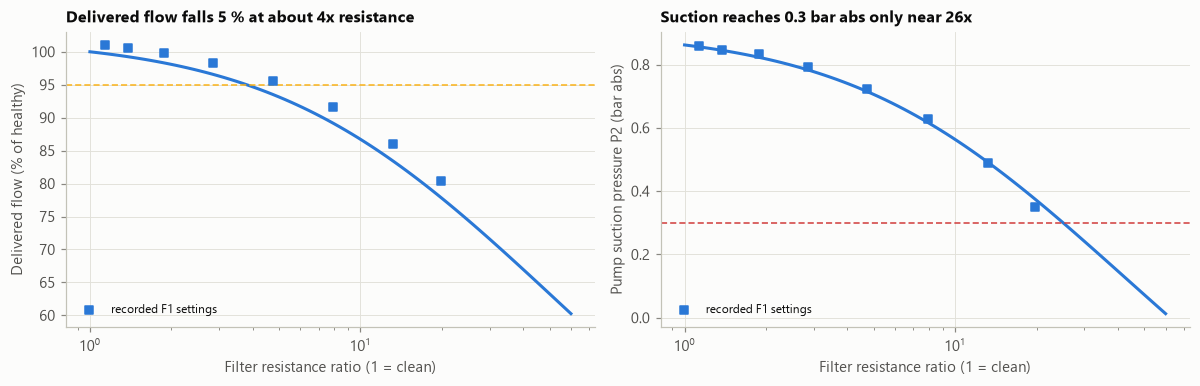

Flow drops 5 % at a filter resistance ratio of about 4x; suction pressure falls below 0.3 bar abs at about 26x.


In [12]:
sweep = []
for s_f in np.geomspace(1, 60, 80):
    o = rig_all.solve(s_f=s_f)
    if o["converged"]:
        sweep.append({"filter resistance ratio": s_f, "Q": o["Q"], "P2 (bar abs)": o["P2"]})
sweep = pd.DataFrame(sweep)
q0 = sweep["Q"].iloc[0]
lim_q = sweep.loc[sweep["Q"] < 0.95 * q0, "filter resistance ratio"].min()
lim_p = sweep.loc[sweep["P2 (bar abs)"] < 0.3, "filter resistance ratio"].min()
fig, axes = plt.subplots(1, 2, figsize=(11, 3.6))
axes[0].plot(sweep["filter resistance ratio"], 100 * sweep["Q"] / q0, color=pl.CONDITION_COLORS["F1"])
axes[0].axhline(95, color=pl.STATUS["warning"], lw=1, ls=(0, (4, 2)))
axes[0].set_ylabel("Delivered flow (% of healthy)")
axes[1].plot(sweep["filter resistance ratio"], sweep["P2 (bar abs)"], color=pl.CONDITION_COLORS["F1"])
axes[1].axhline(0.3, color=pl.STATUS["critical"], lw=1, ls=(0, (4, 2)))
axes[1].set_ylabel("Pump suction pressure P2 (bar abs)")
f1r = runs[runs["condition"] == "F1"]
f1_ratio = 1 + day[day["condition"] == "F1"].groupby("run_id")["r_filter"].mean()
for ax, col in zip(axes, ["Q", "P2"]):
    y = 100 * f1r[col] / q0 if col == "Q" else f1r[col]
    ax.scatter(f1_ratio.reindex(f1r.index), y, color=pl.CONDITION_COLORS["F1"], marker="s", s=22, zorder=3,
               label="recorded F1 settings")
    ax.set_xscale("log")
    ax.set_xlabel("Filter resistance ratio (1 = clean)")
    ax.legend(fontsize=8, loc="lower left")
axes[0].set_title("Delivered flow falls 5 % at about 4x resistance")
axes[1].set_title("Suction reaches 0.3 bar abs only near 26x")
fig.tight_layout()
pl.save(fig, "06_whatif_filter")
plt.show()
print(f"Flow drops 5 % at a filter resistance ratio of about {lim_q:.0f}x; "
      f"suction pressure falls below 0.3 bar abs at about {lim_p:.0f}x.")

On this rig at 400 rpm the filter can reach about 4 times its clean resistance before delivery
falls by 5 %, and suction pressure only approaches cavitation territory (0.3 bar abs) at about 26
times. The filter residual sees the clog from about 1.4 times (the 20 % setting, notebook 03), much
earlier than either. So a twin can plan the filter change on the resistance ratio and keep suction
pressure as a hard safety limit, instead of waiting for lost flow. (Bardakis, 2019, found flow even
less sensitive on the later rig at 1140 rpm.)

**Closing the loop: can pump speed compensate?** A digital twin, unlike a shadow, may act on the
asset. One candidate action for a clogging filter or a worn pump is to raise the pump speed to hold
the delivered flow. With the pump flow scaled with speed (constant displacement, notebook 05):

In [13]:
def flow_at_speed(rpm, **fault):
    m = sm.RigModel(**{**rig_all.__dict__, "q0": rig_all.q0 * rpm / 400.0})
    return m.solve(**fault)


target = rig_all.solve()["Q"]
act = []
for label, fault in [("filter 10x resistance", {"s_f": 10}), ("filter 25x resistance", {"s_f": 25}),
                     ("pump bypass, 20 % of flow lost", {"g_b": 0.42}), ("leak, 20 % of flow lost", {"g_l": 0.48})]:
    rpms = np.arange(400, 801, 5)
    sols = [flow_at_speed(r, **fault) for r in rpms]
    ok = [r for r, o in zip(rpms, sols) if o["converged"] and o["Q"] >= target]
    need = ok[0] if ok else np.nan
    o = flow_at_speed(need, **fault) if ok else {"P2": np.nan, "P3": np.nan}
    act.append({"fault": label, "speed to restore flow (rpm)": need, "P2 at that speed (bar abs)": o["P2"],
                "P3 at that speed (bar abs)": o["P3"]})
pd.DataFrame(act)

,fault,speed to restore flow (rpm),P2 at that speed (bar abs),P3 at that speed (bar abs)
0,filter 10x resistance,485,0.425,1.324
1,filter 25x resistance,625,-0.305,1.325
2,"pump bypass, 20 % of flow lost",515,0.816,1.326
3,"leak, 20 % of flow lost",520,0.820,1.399


Raising speed restores flow for a bypass or leak at a modest pressure cost, but for a clogged filter
it pulls the suction pressure down further. At 25x resistance the model asks for a negative absolute
suction pressure, which is physically impossible: the pump would cavitate long before, so speed
cannot compensate a badly clogged filter. A prescriptive twin therefore needs
the suction limit as a constraint, and for a leak, compensating is the wrong action: fuel leaks are a
safety issue (Bardakis, 2019), so the right response is to isolate. This is the kind of reasoning that
turns diagnosis into decision support, and why the twin's actions must be designed per fault.

## 6. From what the shadow learned to the twin's specification

Each limit met in this project becomes a requirement. Full text and justification:
`docs/task5_digital_twin_design.md`.

| Lesson from the shadow | Evidence | Requirement for the twin |
|---|---|---|
| Healthy behaviour drifts by 1-3.5 % over a day; drift mimics pump and leak faults | notebooks 03, 04 (F5 10 % false isolation) | measure fluid temperature at pump inlet; healthy reference recorded across temperatures; slip k_s modelled as a function of temperature |
| P3-P5 are gauge, P1-P2 absolute, atmosphere not logged | notebook 01 | log atmospheric pressure, or make all transducers the same reference |
| P5 clips at 0 bar gauge | notebook 01 | transducer range that covers sub-atmospheric pressure at the nozzle outlet |
| Pump ripple at shaft and mesh orders carries condition information | notebook 02 | keep >= 200 Hz sampling on at least P2/P3 (the PLC's 200 ms period cannot see it) |
| Pump slip changes between days and installations; displacement does not | notebook 05 | pump model with fixed D and an online-estimated k_s; k_s trend as the pump-wear indicator |
| Labels tied to time of day inflate every classifier score | notebook 04 | randomised, repeated fault-injection schedule; healthy runs interleaved with faults |
| Physics-trained classifier generalises to unseen real faults | section 4 | keep the network model as the twin's virtual entity; qualify its noise and drift against data |
| Mildest settings are below the detection limit | notebooks 03, 04 | state detection limits per fault in physical units; use trend over hours, not single windows, for incipient faults |
| Wrong answers must not look confident | section 3 | quality indicator per function (DNV-RP-A204), shown with every result |